In [5]:
import numpy as np
import matplotlib.pyplot as plt

celsius = np.linspace(-20, 100, 50)
fahrenheit = 1.8 * celsius + 32

w = 0
b = 0

lr = 0.0005
epochs = 1000

weights = []
biases = []
mse_history = []

for epoch in range(epochs):
    total_error = 0
    for x, y_true in zip(celsius, fahrenheit):
        y_pred = w * x + b
        error = y_true - y_pred

        w = w + lr * error * x
        b = b + lr * error

        total_error = total_error + error ** 2

    weights.append(w)
    biases.append(b)
    mse_history.append(total_error / len(celsius))

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, MSE: {mse_history[-1]:.4f}, weight: {w:.4f}, bias: {b:.4f}")

predicted = w * celsius + b

# plt.figure(figsize=(10, 5))
# plt.plot(celsius, fahrenheit, label='True', linestyle='--')
# plt.plot(celsius, predicted, label='Predicted', linestyle='-')
# plt.xlabel("Celsius")
# plt.ylabel("Fahrenheit")
# plt.legend()
# plt.grid(True)
# plt.title("Perceptron - Celsius to Fahrenheit")
# plt.show()

# plt.figure(figsize=(10, 5))
# plt.plot(weights, label='Weight w')
# plt.plot(biases, label='Bias b')
# plt.xlabel("Epoch")
# plt.ylabel("Value")
# plt.title("Evolution of Weight and Bias")
# plt.grid(True)
# plt.legend()
# plt.savefig("evolucao_pesos_bias.png", dpi=300)
# plt.show()
# print("Graph saved as 'evolucao_pesos_bias.png'")

# # Plot 3: Error evolution
# plt.figure(figsize=(10, 5))
# plt.yscale("log")
# plt.plot(mse_history, label='MSE')
# plt.xlabel("Epoch")
# plt.ylabel("Mean Squared Error")
# plt.title("Error Evolution Over Epochs")
# plt.grid(True)
# plt.legend()
# plt.savefig("evolucao_erro_mse.png", dpi=300)
# plt.show()
# print("Graph saved as 'evolucao_erro_mse.png'")



Epoch 0, MSE: 430.2363, weight: 2.1168, bias: 0.2730
Epoch 100, MSE: 63.7984, weight: 1.9295, bias: 18.9411
Epoch 200, MSE: 10.8085, weight: 1.8533, bias: 26.6249
Epoch 300, MSE: 1.8311, weight: 1.8219, bias: 29.7876
Epoch 400, MSE: 0.3102, weight: 1.8090, bias: 31.0894
Epoch 500, MSE: 0.0526, weight: 1.8037, bias: 31.6252
Epoch 600, MSE: 0.0089, weight: 1.8015, bias: 31.8457
Epoch 700, MSE: 0.0015, weight: 1.8006, bias: 31.9365
Epoch 800, MSE: 0.0003, weight: 1.8003, bias: 31.9739
Epoch 900, MSE: 0.0000, weight: 1.8001, bias: 31.9892


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Learned weight: nan, bias: nan
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


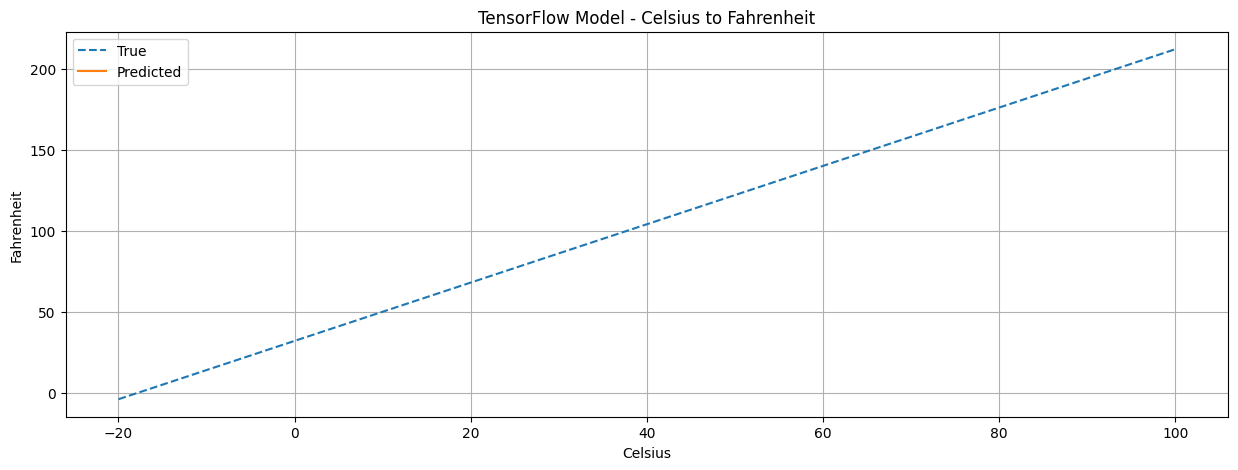

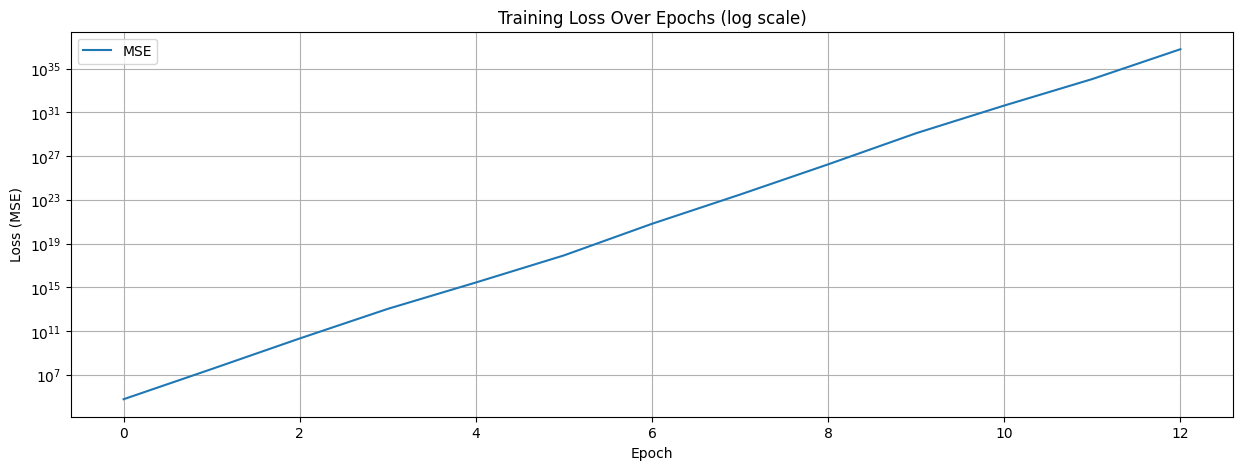

In [6]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Generate training data
celsius = np.linspace(-20, 100, 50)
fahrenheit = 1.8 * celsius + 32

# Reshape inputs for TensorFlow (as 2D arrays)
X = celsius.reshape(-1, 1)
y = fahrenheit.reshape(-1, 1)

# Build a simple linear model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(units=1, input_shape=[1])
])

# Compile model with optimizer and loss
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              loss='mean_squared_error')

# Train the model and store history
history = model.fit(X, y, epochs=1000, verbose=0)

# Print learned parameters
weights, bias = model.layers[0].get_weights()
print(f"Learned weight: {weights[0][0]:.4f}, bias: {bias[0]:.4f}")

# Plot 1: True vs Predicted
predicted = model.predict(X)

plt.figure(figsize=(15, 5))
plt.plot(celsius, fahrenheit, label='True', linestyle='--')
plt.plot(celsius, predicted, label='Predicted', linestyle='-')
plt.xlabel("Celsius")
plt.ylabel("Fahrenheit")
plt.legend()
plt.grid(True)
plt.title("TensorFlow Model - Celsius to Fahrenheit")
plt.savefig("tf_grafico_celsius_fahrenheit.png", dpi=300)
plt.show()

# Plot 2: Loss evolution (MSE)
plt.figure(figsize=(15, 5))
plt.plot(history.history['loss'], label='MSE')
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Training Loss Over Epochs (log scale)")
plt.grid(True)
plt.legend()
plt.savefig("tf_loss_evolution.png", dpi=300)
plt.show()
